#  2D steady heat conduction
### Natural coordinates → Jacobian → element stiffness → global assembly → temperature solution

Starting from **$4\times 4$** conduction stiffness matrix of a four-node bilinear rectangle to assembling a **$9\times 9$** system for four elements, apply internal heat generation, inward heat flux, and convection, then **directly solve all nine unknown nodal temperatures** using

$$\boxed{\theta=T-T_\infty.}$$



**Variables:** $a$ = element width ($x$), $b$ = element height ($y$), $t$ = out-of-plane thickness, $k$ = isotropic conductivity, $Q_g$ = volumetric generation, $q_0$ = *inward* left-edge heat flux, $h$ = right-edge convection coefficient. All four elements use local ordering $1\to2\to3\to4$ counterclockwise, starting at bottom-left.

## 1 · Strong form, boundary conditions, and weak form

For constant isotropic conductivity,

$$-\frac{\partial}{\partial x}\left(k\frac{\partial\theta}{\partial x}\right)-\frac{\partial}{\partial y}\left(k\frac{\partial\theta}{\partial y}\right)=Q_g.$$

Outward normal $\mathbf n$ is used for boundary flux $q_n=-k\,\partial\theta/\partial n$:

| Boundary | Physical condition | Mathematical condition |
|---|---|---|
| $x=0$ | Uniform heat flux **into** slab | $-k\partial\theta/\partial n=-q_0$ |
| $x=L_x$ | Convection | $-k\partial\theta/\partial n=h\theta$ |
| $y=0,L_y$ | Insulated | $-k\partial\theta/\partial n=0$ |

After multiplying by test function $w$, integrating by parts, and imposing the natural boundary conditions, the element weak form is

$$\boxed{\begin{aligned}
&\int_{\Omega_e}kt\left(\frac{\partial w}{\partial x}\frac{\partial\theta}{\partial x}+\frac{\partial w}{\partial y}\frac{\partial\theta}{\partial y}\right)\,dx\,dy
+\int_{\Gamma_h^e}htw\theta\,ds\\
&\quad=\int_{\Omega_e}Q_gtw\,dx\,dy+\int_{\Gamma_q^e}q_0tw\,ds.
\end{aligned}}$$

Here,  $dV=t\,dx\,dy$, while a physical side-surface area is $dS=t\,ds$. Thus the thickness multiplies both the area and the boundary integrals. The insulated boundaries have no contribution.

In [ ]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
sp.init_printing(use_latex='mathjax')


xi, eta = sp.symbols('xi eta', real=True)
a, b, t, k, Qg, q0, h, Tinf = sp.symbols(
    r'a b t k Q_g q_0 h T_{\infty}', positive=True, real=True
)
x0, y0 = sp.symbols('x_0 y_0', real=True)
print('Symbols and packages ready.')

Symbols and packages ready.


## 2 · Reference Q4 element and four-element mesh

Natural coordinates $(\xi,\eta)\in[-1,1]^2$ with local nodes

$$1=(-1,-1),\;2=(1,-1),\;3=(1,1),\;4=(-1,1).$$

For a $2\times2$ mesh, **global nodes** are numbered from left to right, bottom to top:

$$\text{CONN}=\begin{bmatrix}1&2&5&4\\2&3&6&5\\4&5&8&7\\5&6&9&8\end{bmatrix}.$$

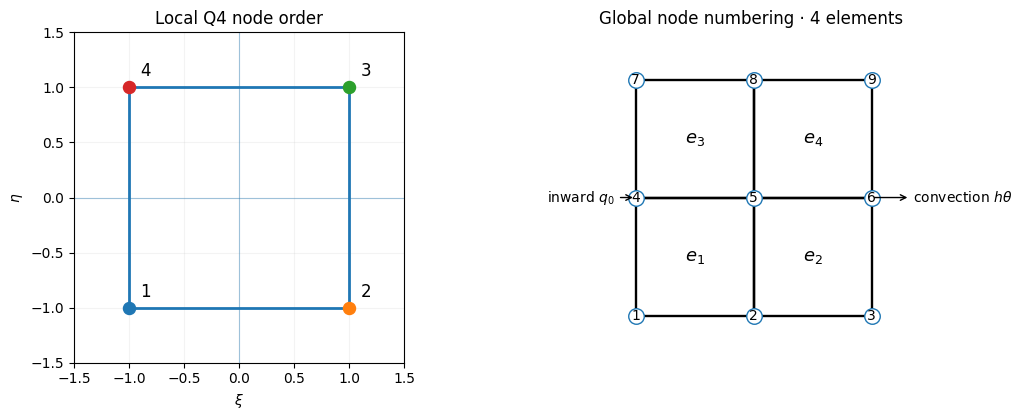

**Connectivity (rows = elements, columns = local nodes 1–4):**

⎡1  2  5  4⎤
⎢          ⎥
⎢2  3  6  5⎥
⎢          ⎥
⎢4  5  8  7⎥
⎢          ⎥
⎣5  6  9  8⎦

In [ ]:
# One symbolic-element reference and one four-element physical topology.
fig, axes = plt.subplots(1, 2, figsize=(11.3, 4.3))
ref_nodes = np.array([[-1,-1],[1,-1],[1,1],[-1,1]], dtype=float)
ref_closed = np.vstack((ref_nodes, ref_nodes[0]))
axes[0].plot(ref_closed[:,0], ref_closed[:,1], linewidth=2.0)
axes[0].axhline(0, lw=.8, alpha=.4); axes[0].axvline(0, lw=.8, alpha=.4)
for ni, (xx, yy) in enumerate(ref_nodes,1):
    axes[0].scatter(xx, yy, s=75, zorder=3)
    axes[0].annotate(str(ni), (xx, yy), xytext=(8,8), textcoords='offset points', fontsize=12)
axes[0].set(xlim=(-1.5,1.5), ylim=(-1.5,1.5), xlabel=r'$\xi$', ylabel=r'$\eta$', title='Local Q4 node order')
axes[0].set_aspect('equal'); axes[0].grid(alpha=.15)

mesh_xy = {1:(0,0),2:(1,0),3:(2,0),4:(0,1),5:(1,1),6:(2,1),7:(0,2),8:(1,2),9:(2,2)}
conn = np.array([[1,2,5,4],[2,3,6,5],[4,5,8,7],[5,6,9,8]], dtype=int)
for e, nodes in enumerate(conn,1):
    pts = np.array([mesh_xy[int(n)] for n in nodes]); pts = np.vstack([pts, pts[0]])
    axes[1].plot(pts[:,0], pts[:,1], 'k-', lw=1.7)
    axes[1].text(pts[:-1,0].mean(),pts[:-1,1].mean(),rf'$e_{e}$',ha='center',va='center',fontsize=13)
for n,(xx,yy) in mesh_xy.items():
    axes[1].scatter(xx,yy,s=125,facecolor='white',edgecolor='C0',zorder=3)
    axes[1].text(xx,yy,str(n),ha='center',va='center',zorder=4, fontsize=10)
axes[1].annotate(r'inward $q_0$', xy=(0,1), xytext=(-.75,1), arrowprops=dict(arrowstyle='->'),va='center')
axes[1].annotate(r'convection $h\theta$', xy=(2,1), xytext=(2.35,1), arrowprops=dict(arrowstyle='<-'),va='center')
axes[1].set(xlim=(-1,2.95), ylim=(-.4,2.4), xlabel=r'$x/a$', ylabel=r'$y/b$', title='Global node numbering · 4 elements')
axes[1].set_aspect('equal'); axes[1].axis('off')
fig.tight_layout(); plt.show()

display(Markdown('**Connectivity (rows = elements, columns = local nodes 1–4):**'))
display(sp.Matrix(conn.tolist()))

## 3 · Bilinear interpolation and Galerkin approximation

$$\begin{aligned}
N_1&=\frac14(1-\xi)(1-\eta), &N_2&=\frac14(1+\xi)(1-\eta),\\
N_3&=\frac14(1+\xi)(1+\eta), &N_4&=\frac14(1-\xi)(1+\eta).
\end{aligned}$$

With $[N]=[N_1\;N_2\;N_3\;N_4]$,

$$\theta^{(e)}=[N]\{\theta\}^{(e)},\qquad w^{(e)}=[N]\{w\}^{(e)},\qquad \{\theta\}^{(e)}=\begin{bmatrix}\theta_1&\theta_2&\theta_3&\theta_4\end{bmatrix}^{T}.$$

The Galerkin method chooses each weight $w=N_i$, giving four equations per element.

In [ ]:
N = sp.Matrix([ (1-xi)*(1-eta)/4, (1+xi)*(1-eta)/4,
                (1+xi)*(1+eta)/4, (1-xi)*(1+eta)/4 ])
print('Shape functions:'); display(N)
assert sp.simplify(sum(N)-1)==0
print('Partition of unity: sum(N_i) =', sp.simplify(sum(N)))
print('Kronecker property at the four nodes:')
local_nodes=[(-1,-1),(1,-1),(1,1),(-1,1)]
display(sp.Matrix([[N[i].subs({xi:u, eta:v}) for i in range(4)] for u,v in local_nodes]))

Shape functions:


⎡(1 - η)⋅(1 - ξ)⎤
⎢───────────────⎥
⎢       4       ⎥
⎢               ⎥
⎢(1 - η)⋅(ξ + 1)⎥
⎢───────────────⎥
⎢       4       ⎥
⎢               ⎥
⎢(η + 1)⋅(ξ + 1)⎥
⎢───────────────⎥
⎢       4       ⎥
⎢               ⎥
⎢(1 - ξ)⋅(η + 1)⎥
⎢───────────────⎥
⎣       4       ⎦

Partition of unity: sum(N_i) = 1
Kronecker property at the four nodes:


⎡1  0  0  0⎤
⎢          ⎥
⎢0  1  0  0⎥
⎢          ⎥
⎢0  0  1  0⎥
⎢          ⎥
⎣0  0  0  1⎦

## 4 · Isoparametric transformation and Jacobian

For an axis-aligned rectangular element with its bottom-left corner at $(x_0,y_0)$, the physical nodal positions are

$$\{x_i\}=\{x_0,x_0+a,x_0+a,x_0\},\qquad
\{y_i\}=\{y_0,y_0,y_0+b,y_0+b\}.$$

Applying the same shape functions to geometry gives

$$\boxed{x=x_0+\frac a2(1+\xi),\qquad y=y_0+\frac b2(1+\eta).}$$

With $J=\partial(x,y)/\partial(\xi,\eta)$,

$$\boxed{[J]=\begin{bmatrix}a/2&0\\0&b/2\end{bmatrix},\quad |J|=\frac{ab}{4},\quad dx\,dy=|J|\,d\xi\,d\eta.}$$

For this $J$, the gradient transformation is

$$\begin{bmatrix}\partial N_i/\partial x\\\partial N_i/\partial y\end{bmatrix}
=[J]^{-T}\begin{bmatrix}\partial N_i/\partial\xi\\\partial N_i/\partial\eta\end{bmatrix}.$$

In [ ]:
Xnodes=sp.Matrix([x0,x0+a,x0+a,x0])
Ynodes=sp.Matrix([y0,y0,y0+b,y0+b])
x_map=sp.expand((N.T*Xnodes)[0]); y_map=sp.expand((N.T*Ynodes)[0])
J=sp.Matrix([[sp.diff(x_map,xi),sp.diff(x_map,eta)],
             [sp.diff(y_map,xi),sp.diff(y_map,eta)]])
detJ=sp.factor(J.det())
dN_nat=sp.Matrix([[sp.diff(ni,xi) for ni in N],
                 [sp.diff(ni,eta) for ni in N]])
Bmat=sp.simplify(J.inv().T * dN_nat)
for lab,obj in [('x(xi,eta)',x_map),('y(xi,eta)',y_map),('Jacobian J',J),
                ('det(J)',detJ),('Gradient matrix B',Bmat)]:
    display(Markdown('**'+lab+'**')); display(obj)

**x(xi,eta)**

a⋅ξ   a     
─── + ─ + x₀
 2    2     

**y(xi,eta)**

b⋅η   b     
─── + ─ + y₀
 2    2     

**Jacobian J**

⎡a   ⎤
⎢─  0⎥
⎢2   ⎥
⎢    ⎥
⎢   b⎥
⎢0  ─⎥
⎣   2⎦

**det(J)**

a⋅b
───
 4 

**Gradient matrix B**

⎡η - 1  1 - η   η + 1  -η - 1⎤
⎢─────  ─────   ─────  ──────⎥
⎢ 2⋅a    2⋅a     2⋅a    2⋅a  ⎥
⎢                            ⎥
⎢ξ - 1  -ξ - 1  ξ + 1  1 - ξ ⎥
⎢─────  ──────  ─────  ───── ⎥
⎣ 2⋅b    2⋅b     2⋅b    2⋅b  ⎦

## 5 · Evaluate the $4\times4$ conduction stiffness symbolically

With isotropic conductivity $[D]=kI_2$,

$$\boxed{[K_c^{(e)}]=\int_{-1}^1\!\int_{-1}^1 t\,[B]^T[D][B]\,|J|\,d\xi\,d\eta.}$$

Equivalently, the $(i,j)$ entry is

$$K_{c,ij}^{(e)}=kt\int_{-1}^1\!\int_{-1}^1
\left(\frac{\partial N_i}{\partial x}\frac{\partial N_j}{\partial x}
+\frac{\partial N_i}{\partial y}\frac{\partial N_j}{\partial y}\right)\frac{ab}{4}\,d\xi\,d\eta.$$

The two directional matrices can be integrated separately and then summed.

In [ ]:
def integrate_square(expr):
    return sp.simplify(sp.integrate(sp.integrate(sp.expand(expr), (xi,-1,1)), (eta,-1,1)))

Kx = sp.Matrix(4,4,lambda i,j: integrate_square(k*t*detJ*Bmat[0,i]*Bmat[0,j]))
Ky = sp.Matrix(4,4,lambda i,j: integrate_square(k*t*detJ*Bmat[1,i]*Bmat[1,j]))
Kc = sp.simplify(Kx+Ky)
for label,mat in [('x-direction: K_x', Kx),('y-direction: K_y',Ky),('conduction K_c = K_x + K_y',Kc)]:
    display(Markdown('**'+label+'**')); display(mat)
print('Checks: K is symmetric =',Kc==Kc.T,', K * ones =',Kc*sp.ones(4,1))

**x-direction: K_x**

⎡ b⋅k⋅t   -b⋅k⋅t   -b⋅k⋅t    b⋅k⋅t ⎤
⎢ ─────   ───────  ───────   ───── ⎥
⎢  3⋅a      3⋅a      6⋅a      6⋅a  ⎥
⎢                                  ⎥
⎢-b⋅k⋅t    b⋅k⋅t    b⋅k⋅t   -b⋅k⋅t ⎥
⎢───────   ─────    ─────   ───────⎥
⎢  3⋅a      3⋅a      6⋅a      6⋅a  ⎥
⎢                                  ⎥
⎢-b⋅k⋅t    b⋅k⋅t    b⋅k⋅t   -b⋅k⋅t ⎥
⎢───────   ─────    ─────   ───────⎥
⎢  6⋅a      6⋅a      3⋅a      3⋅a  ⎥
⎢                                  ⎥
⎢ b⋅k⋅t   -b⋅k⋅t   -b⋅k⋅t    b⋅k⋅t ⎥
⎢ ─────   ───────  ───────   ───── ⎥
⎣  6⋅a      6⋅a      3⋅a      3⋅a  ⎦

**y-direction: K_y**

⎡ a⋅k⋅t    a⋅k⋅t   -a⋅k⋅t   -a⋅k⋅t ⎤
⎢ ─────    ─────   ───────  ───────⎥
⎢  3⋅b      6⋅b      6⋅b      3⋅b  ⎥
⎢                                  ⎥
⎢ a⋅k⋅t    a⋅k⋅t   -a⋅k⋅t   -a⋅k⋅t ⎥
⎢ ─────    ─────   ───────  ───────⎥
⎢  6⋅b      3⋅b      3⋅b      6⋅b  ⎥
⎢                                  ⎥
⎢-a⋅k⋅t   -a⋅k⋅t    a⋅k⋅t    a⋅k⋅t ⎥
⎢───────  ───────   ─────    ───── ⎥
⎢  6⋅b      3⋅b      3⋅b      6⋅b  ⎥
⎢                                  ⎥
⎢-a⋅k⋅t   -a⋅k⋅t    a⋅k⋅t    a⋅k⋅t ⎥
⎢───────  ───────   ─────    ───── ⎥
⎣  3⋅b      6⋅b      6⋅b      3⋅b  ⎦

**conduction K_c = K_x + K_y**

⎡      ⎛ 2    2⎞         ⎛ 2      2⎞        ⎛   2    2⎞       ⎛     2    2⎞⎤
⎢  k⋅t⋅⎝a  + b ⎠     k⋅t⋅⎝a  - 2⋅b ⎠    k⋅t⋅⎝- a  - b ⎠   k⋅t⋅⎝- 2⋅a  + b ⎠⎥
⎢  ─────────────     ───────────────    ───────────────   ─────────────────⎥
⎢      3⋅a⋅b              6⋅a⋅b              6⋅a⋅b              6⋅a⋅b      ⎥
⎢                                                                          ⎥
⎢     ⎛ 2      2⎞         ⎛ 2    2⎞        ⎛     2    2⎞       ⎛   2    2⎞ ⎥
⎢ k⋅t⋅⎝a  - 2⋅b ⎠     k⋅t⋅⎝a  + b ⎠    k⋅t⋅⎝- 2⋅a  + b ⎠   k⋅t⋅⎝- a  - b ⎠ ⎥
⎢ ───────────────     ─────────────    ─────────────────   ─────────────── ⎥
⎢      6⋅a⋅b              3⋅a⋅b              6⋅a⋅b              6⋅a⋅b      ⎥
⎢                                                                          ⎥
⎢     ⎛   2    2⎞       ⎛     2    2⎞        ⎛ 2    2⎞         ⎛ 2      2⎞ ⎥
⎢ k⋅t⋅⎝- a  - b ⎠   k⋅t⋅⎝- 2⋅a  + b ⎠    k⋅t⋅⎝a  + b ⎠     k⋅t⋅⎝a  - 2⋅b ⎠ ⎥
⎢ ───────────────   ─────────────────    ─────────────     ─────────────── ⎥

Checks: K is symmetric = True , K * ones = Matrix([[k*t*(-2*a**2 + b**2)/(6*a*b) + k*t*(-a**2 - b**2)/(6*a*b) + k*t*(a**2 - 2*b**2)/(6*a*b) + k*t*(a**2 + b**2)/(3*a*b)], [k*t*(-2*a**2 + b**2)/(6*a*b) + k*t*(-a**2 - b**2)/(6*a*b) + k*t*(a**2 - 2*b**2)/(6*a*b) + k*t*(a**2 + b**2)/(3*a*b)], [k*t*(-2*a**2 + b**2)/(6*a*b) + k*t*(-a**2 - b**2)/(6*a*b) + k*t*(a**2 - 2*b**2)/(6*a*b) + k*t*(a**2 + b**2)/(3*a*b)], [k*t*(-2*a**2 + b**2)/(6*a*b) + k*t*(-a**2 - b**2)/(6*a*b) + k*t*(a**2 - 2*b**2)/(6*a*b) + k*t*(a**2 + b**2)/(3*a*b)]])


### Compact coefficient representation (symbolic)

Define

$$\begin{aligned}
A &=2\left(\frac ba+\frac ab\right),\\
B &=-2\frac ba+\frac ab,\\
C &=-\left(\frac ba+\frac ab\right),\\
D &=\frac ba-2\frac ab.
\end{aligned}$$

Then the matrix on every one of the four identical rectangles is

$$\boxed{[K_c^{(e)}]=\frac{kt}{6}\begin{bmatrix}A&B&C&D\\B&A&D&C\\C&D&A&B\\D&C&B&A\end{bmatrix}.}$$

This is **conduction only**. Convection is a *separate boundary stiffness contribution* for elements $e_2$ and $e_4$ on the right edge.

In [ ]:
A,Bc,C,D = sp.symbols('A B C D',real=True)
coeff={A:2*(b/a+a/b), Bc:-2*b/a+a/b, C:-(b/a+a/b), D:b/a-2*a/b}
Mloc=sp.Matrix([[A,Bc,C,D],[Bc,A,D,C],[C,D,A,Bc],[D,C,Bc,A]])
assert sp.simplify(Kc-(k*t/6)*Mloc.subs(coeff))==sp.zeros(4)
print('Verified: computed integral equals (k t/6) times the A,B,C,D matrix.')
display(Mloc)

Verified: computed integral equals (k t/6) times the A,B,C,D matrix.


⎡A  B  C  D⎤
⎢          ⎥
⎢B  A  D  C⎥
⎢          ⎥
⎢C  D  A  B⎥
⎢          ⎥
⎣D  C  B  A⎦

## 6 · Element source vector and boundary contributions

**Uniform internal generation (every element):**

$$\{F_g^{(e)}\}=Q_gt\int_{-1}^{1}\!\int_{-1}^{1}[N]^T|J|\,d\xi\,d\eta
=\boxed{\frac{Q_gtab}{4}\begin{bmatrix}1\\1\\1\\1\end{bmatrix}}.$$

**Inward heat flux on the LEFT edge** ($\xi=-1$, local nodes $1$ and $4$):

$$ds=\frac b2\,d\eta,\qquad
\boxed{\{F_q^{(e)}\}=\frac{q_0tb}{2}\begin{bmatrix}1\\0\\0\\1\end{bmatrix}.}$$

**Convection on the RIGHT edge** ($\xi=+1$, local nodes $2$ and $3$):

$$\boxed{[K_h^{(e)}]=\frac{htb}{6}
\begin{bmatrix}0&0&0&0\\0&2&1&0\\0&1&2&0\\0&0&0&0\end{bmatrix}.}$$

Because we solve for $\theta=T-T_\infty$, the ambient-temperature load term $hT_\infty$ is **absent**.

In [ ]:
Fg_e=sp.Matrix([sp.simplify(Qg*t*integrate_square(detJ*N[i])) for i in range(4)])
Nleft=sp.simplify(N.subs(xi,-1)); Nright=sp.simplify(N.subs(xi,1))
Fq_left=sp.Matrix([sp.integrate(q0*t*b/2*Nleft[i],(eta,-1,1)) for i in range(4)])
Kh_right=sp.Matrix(4,4,lambda i,j: sp.simplify(sp.integrate(h*t*b/2*Nright[i]*Nright[j], (eta,-1,1))))
for label,obj in [('Generation load (all 4 elements)', Fg_e),
                  ('Left prescribed-flux load (elements 1 and 3 only)',Fq_left),
                  ('Right convection stiffness (elements 2 and 4 only)',Kh_right)]:
    display(Markdown('**'+label+'**')); display(obj)
assert sp.simplify(Fg_e-Qg*t*a*b/4*sp.ones(4,1))==sp.zeros(4,1)

**Generation load (all 4 elements)**

⎡Q_g⋅a⋅b⋅t⎤
⎢─────────⎥
⎢    4    ⎥
⎢         ⎥
⎢Q_g⋅a⋅b⋅t⎥
⎢─────────⎥
⎢    4    ⎥
⎢         ⎥
⎢Q_g⋅a⋅b⋅t⎥
⎢─────────⎥
⎢    4    ⎥
⎢         ⎥
⎢Q_g⋅a⋅b⋅t⎥
⎢─────────⎥
⎣    4    ⎦

**Left prescribed-flux load (elements 1 and 3 only)**

⎡b⋅q₀⋅t⎤
⎢──────⎥
⎢  2   ⎥
⎢      ⎥
⎢  0   ⎥
⎢      ⎥
⎢  0   ⎥
⎢      ⎥
⎢b⋅q₀⋅t⎥
⎢──────⎥
⎣  2   ⎦

**Right convection stiffness (elements 2 and 4 only)**

⎡0    0      0    0⎤
⎢                  ⎥
⎢   b⋅h⋅t  b⋅h⋅t   ⎥
⎢0  ─────  ─────  0⎥
⎢     3      6     ⎥
⎢                  ⎥
⎢   b⋅h⋅t  b⋅h⋅t   ⎥
⎢0  ─────  ─────  0⎥
⎢     6      3     ⎥
⎢                  ⎥
⎣0    0      0    0⎦

## 7 · Assemble the full global $9\times9$ system

The global system is

$$\boxed{\underbrace{[K_{c,G}]+[K_{h,G}]}_{[K_G]}\{\theta_G\}
=\underbrace{\{F_{g,G}\}+\{F_{q,G}\}}_{\{F_G\}}.}$$

Each element contributes according to the connectivity mapping:

$$K_G[\mathrm{CONN}_{ei},\mathrm{CONN}_{ej}]\mathrel{+}=K^{(e)}[i,j],\quad
F_G[\mathrm{CONN}_{ei}]\mathrel{+}=F^{(e)}[i].$$

The implementation below initializes the global arrays with zeros and adds each local contribution. **Only** $e_1$ and $e_3$ receive $F_q$; **only** $e_2$ and $e_4$ receive $K_h$.

In [ ]:
Kc_G = sp.zeros(9); Kh_G = sp.zeros(9)
Fg_G = sp.zeros(9,1); Fq_G = sp.zeros(9,1)
for e, nodes in enumerate(conn):
    for i, gni in enumerate(nodes):
        I=int(gni)-1
        Fg_G[I]+=Fg_e[i]
        if e in (0,2): Fq_G[I]+=Fq_left[i]
        for j, gnj in enumerate(nodes):
            Jidx=int(gnj)-1
            Kc_G[I,Jidx]+=Kc[i,j]
            if e in (1,3): Kh_G[I,Jidx]+=Kh_right[i,j]

K_G=sp.simplify(Kc_G+Kh_G); F_G=sp.simplify(Fg_G+Fq_G)
# The full 9x9 conduction matrix is most readable with factor (k*t/6) removed.
Mglob=sp.Matrix(9,9,lambda i,j: 0)
for nodes in conn:
    for i,I in enumerate(nodes):
        for j,Jidx in enumerate(nodes): Mglob[int(I)-1,int(Jidx)-1]+=Mloc[i,j]

print('Global conduction matrix: K_c,G = (k*t/6) * the following 9 x 9 matrix')
display(Mglob)
print('Global convection matrix: K_h,G = (h*t*b/6) * the following 9 x 9 matrix')
display(sp.simplify(6*Kh_G/(h*t*b)))
print('Global generation vector F_g,G = (Q_g*t*a*b/4) *')
display(sp.simplify(4*Fg_G/(Qg*t*a*b)))
print('Global left-flux vector F_q,G = (q_0*t*b/2) *')
display(sp.simplify(2*Fq_G/(q0*t*b)))
assert sp.simplify(Kc_G-(k*t/6)*Mglob.subs(coeff))==sp.zeros(9)

Global conduction matrix: K_c,G = (k*t/6) * the following 9 x 9 matrix


⎡A   B   0   D    C    0   0   0   0⎤
⎢                                   ⎥
⎢B  2⋅A  B   C   2⋅D   C   0   0   0⎥
⎢                                   ⎥
⎢0   B   A   0    C    D   0   0   0⎥
⎢                                   ⎥
⎢D   C   0  2⋅A  2⋅B   0   D   C   0⎥
⎢                                   ⎥
⎢C  2⋅D  C  2⋅B  4⋅A  2⋅B  C  2⋅D  C⎥
⎢                                   ⎥
⎢0   C   D   0   2⋅B  2⋅A  0   C   D⎥
⎢                                   ⎥
⎢0   0   0   D    C    0   A   B   0⎥
⎢                                   ⎥
⎢0   0   0   C   2⋅D   C   B  2⋅A  B⎥
⎢                                   ⎥
⎣0   0   0   0    C    D   0   B   A⎦

Global convection matrix: K_h,G = (h*t*b/6) * the following 9 x 9 matrix


⎡0  0  0  0  0  0  0  0  0⎤
⎢                         ⎥
⎢0  0  0  0  0  0  0  0  0⎥
⎢                         ⎥
⎢0  0  2  0  0  1  0  0  0⎥
⎢                         ⎥
⎢0  0  0  0  0  0  0  0  0⎥
⎢                         ⎥
⎢0  0  0  0  0  0  0  0  0⎥
⎢                         ⎥
⎢0  0  1  0  0  4  0  0  1⎥
⎢                         ⎥
⎢0  0  0  0  0  0  0  0  0⎥
⎢                         ⎥
⎢0  0  0  0  0  0  0  0  0⎥
⎢                         ⎥
⎣0  0  0  0  0  1  0  0  2⎦

Global generation vector F_g,G = (Q_g*t*a*b/4) *


⎡1⎤
⎢ ⎥
⎢2⎥
⎢ ⎥
⎢1⎥
⎢ ⎥
⎢2⎥
⎢ ⎥
⎢4⎥
⎢ ⎥
⎢2⎥
⎢ ⎥
⎢1⎥
⎢ ⎥
⎢2⎥
⎢ ⎥
⎣1⎦

Global left-flux vector F_q,G = (q_0*t*b/2) *


⎡1⎤
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢2⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢1⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎣0⎦

The assembled problem is

$$\boxed{[K_G]\{\theta_G\}=\{F_G\},\qquad
\{\theta_G\}=[\theta_1,\theta_2,\ldots,\theta_9]^T.}$$

To make the **nine equations** readable, divide both sides by $kt/6$ and define

$$\beta=\frac{hb}{k},\qquad G=\frac{3Q_gab}{2k},\qquad P=\frac{3q_0b}{k}.$$

With $M_{c,G}=6K_{c,G}/(kt)$ and $M_{h,G}=6K_{h,G}/(htb)$, the system is

$$\boxed{\left[M_{c,G}+\beta M_{h,G}\right]\{\theta_G\}
=G\begin{Bmatrix}1\\2\\1\\2\\4\\2\\1\\2\\1\end{Bmatrix}
+P\begin{Bmatrix}1\\0\\0\\2\\0\\0\\1\\0\\0\end{Bmatrix}.}$$



In [ ]:
beta_sym, G_sym, P_sym = sp.symbols('beta G P', real=True)
theta_syms = sp.symbols('theta_1:10', real=True)
theta_unknowns = sp.Matrix(theta_syms)
Hglob = sp.simplify(6*Kh_G/(h*t*b))
Gglob = sp.simplify(4*Fg_G/(Qg*t*a*b))
Pglob = sp.simplify(2*Fq_G/(q0*t*b))

K_dimensionless = Mglob + beta_sym*Hglob
F_dimensionless = G_sym*Gglob + P_sym*Pglob

print('All nine equations (in A, B, C, D, beta, G, P):')
for i in range(9):
    display(Math(r'\text{Node }' + str(i+1) + r':\quad' +
                 sp.latex(sp.Eq((K_dimensionless*theta_unknowns)[i], F_dimensionless[i]))))

# This exactly represents the original nine equations (no row/column removed).
assert sp.simplify(K_dimensionless.subs({beta_sym:h*b/k}).subs(coeff)*k*t/6 - K_G) == sp.zeros(9)
assert sp.simplify(F_dimensionless.subs({G_sym:3*Qg*a*b/(2*k), P_sym:3*q0*b/k})*k*t/6 - F_G) == sp.zeros(9,1)

All nine equations (in A, B, C, D, beta, G, P):


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 9 · Solve the **full symbolic 9 × 9 system**

We directly solve

$$K_G\begin{Bmatrix}\theta_1\\\theta_2\\\theta_3\\\theta_4\\\theta_5\\\theta_6\\\theta_7\\\theta_8\\\theta_9\end{Bmatrix}=F_G.$$

To avoid impractically large intermediate rational expressions, multiply **all nine equations** by the same nonzero factor $6ab/t$:

$$\underbrace{\frac{6ab}{t}K_G}_{K_*}\{\theta_G\}
=\underbrace{\frac{6ab}{t}F_G}_{F_*}.$$

the matrix stays $9\times9$, all nine unknowns remain, and the same solution is obtained. SymPy's exact fraction-free polynomial-matrix algorithm solves the complete system; it does not assume any temperature symmetry.

In [ ]:
from sympy.polys.matrices import DomainMatrix

# Full 9 x 9 exact symbolic system, in polynomial form.
K_star = sp.simplify((6*a*b/t) * K_G)
F_star = sp.simplify((6*a*b/t) * F_G)
assert K_star.shape == (9, 9)
assert F_star.shape == (9, 1)

# Exact fraction-free solve: numerator / denominator = K_star^{-1} F_star.
K_domain, F_domain = DomainMatrix.from_Matrix(K_star).unify(
    DomainMatrix.from_Matrix(F_star)
)
numerator, denominator = K_domain.solve_den(F_domain, method='charpoly')
raw_solution = numerator.to_Matrix() / denominator.as_expr()
theta_full_symbolic = sp.Matrix([sp.factor(raw_solution[i]) for i in range(9)])

print('Direct solution for ALL NINE independent nodal unknowns:')
for i in range(9):
    display(Math(r'\theta_{' + str(i+1) + r'}=' + sp.latex(theta_full_symbolic[i])))

# Verify each of the nine original, unscaled equations.
residual_symbolic = (K_G*theta_full_symbolic - F_G).applyfunc(sp.simplify)
print('Full symbolic residual [K_G] theta - F_G:')
display(residual_symbolic)
assert residual_symbolic == sp.zeros(9,1)
print('SUCCESS: all nine original equations satisfied exactly.')

Direct solution for ALL NINE independent nodal unknowns:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (3 outputs left out)

<IPython.core.display.Math object>

Full symbolic residual [K_G] theta - F_G:


⎡0⎤
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎣0⎦

SUCCESS: all nine original equations satisfied exactly.


### Result

The nine expressions above are the **output** of the full $9\times9$ symbolic solve. Any equality among nodal values is a *result*, not an assumption. The solution is unique for positive $k$, $h$, $a$, $b$, and $t$.

Recover absolute temperature at each node using

$$\boxed{T_i=T_\infty+\theta_i,\quad i=1,\ldots,9.}$$

Numerical values are substituted in the next section.

## 10 · Full numerical 9 × 9 solve (editable inputs)

Original problem: $L_x=10$ mm, $L_y=5$ mm, $t=5$ mm, $k=0.2$ W/(mm·°C), $Q_g=0.06$ W/mm³. Four rectangular elements give $a=L_x/2$ and $b=L_y/2$.



In [ ]:
# === EDITABLE INPUTS ===
Lx_mm = 10.0                  # given slab width (mm)
Ly_mm = 5.0                   # given slab height (mm)
thickness_mm = 5.0            # given thickness (mm)
conductivity = 0.2            # given W/(mm*deg C)
volumetric_generation = 0.06 # given W/mm^3


q0_demo = 0.02                # W/mm^2, inward on left
h_demo = 0.01                 # W/(mm^2*deg C), convection on right
Tinf_demo = 25.0              # deg C, ambient temperature

if h_demo <= 0 or conductivity <= 0:
    raise ValueError('A unique solution requires positive k and h.')

values = {a:Lx_mm/2, b:Ly_mm/2, t:thickness_mm,
          k:conductivity, Qg:volumetric_generation, q0:q0_demo, h:h_demo}

Knum = np.array(K_G.subs(values), dtype=float)
Fnum = np.array(F_G.subs(values), dtype=float).reshape(9)
print('Full 9 x 9 numerical stiffness matrix K_G (W/deg C):')
print(np.array2string(Knum, precision=6, suppress_small=True))
print('\nFull nine-entry global load vector F_G (W):')
print(np.array2string(Fnum, precision=6, suppress_small=True))

theta_num = np.linalg.solve(Knum, Fnum)  # all nine nodal unknowns
Tnum = theta_num + Tinf_demo
print('\nNine-node temperature solution:')
print(' Node    x(mm)    y(mm)       theta(deg C)       T(deg C)')
for inode in range(1,10):
    xn=((inode-1)%3)*Lx_mm/2
    yn=((inode-1)//3)*Ly_mm/2
    print(f'{inode:5d} {xn:8.3f} {yn:8.3f} {theta_num[inode-1]:18.8f} {Tnum[inode-1]:16.8f}')



# Separate independent verification against the full SYMBOLIC result.
theta_from_symbolic = np.array(theta_full_symbolic.subs(values), dtype=float).reshape(9)
assert np.allclose(theta_num, theta_from_symbolic, rtol=1e-11, atol=1e-10)
print('\nDirect numerical solve matches all nine symbolic solutions.')

Full 9 x 9 numerical stiffness matrix K_G (W/deg C):
[[ 0.833333  0.166667  0.       -0.583333 -0.416667  0.        0.
   0.        0.      ]
 [ 0.166667  1.666667  0.166667 -0.416667 -1.166667 -0.416667  0.
   0.        0.      ]
 [ 0.        0.166667  0.875     0.       -0.416667 -0.5625    0.
   0.        0.      ]
 [-0.583333 -0.416667  0.        1.666667  0.333333  0.       -0.583333
  -0.416667  0.      ]
 [-0.416667 -1.166667 -0.416667  0.333333  3.333333  0.333333 -0.416667
  -1.166667 -0.416667]
 [ 0.       -0.416667 -0.5625    0.        0.333333  1.75      0.
  -0.416667 -0.5625  ]
 [ 0.        0.        0.       -0.583333 -0.416667  0.        0.833333
   0.166667  0.      ]
 [ 0.        0.        0.       -0.416667 -1.166667 -0.416667  0.166667
   1.666667  0.166667]
 [ 0.        0.        0.        0.       -0.416667 -0.5625    0.
   0.166667  0.875   ]]

Full nine-entry global load vector F_G (W):
[1.0625 1.875  0.9375 2.125  3.75   1.875  1.0625 1.875  0.9375]

Nine-node 

## 11 · Evaluate the **2D Q4 interpolated temperature field**

Use the actual four-element connectivity and **all nine solved nodal temperatures**. For any point inside element $e$,

$$T^{(e)}(\xi,\eta)=T_\infty+\sum_{i=1}^{4}N_i(\xi,\eta)\,\theta_{\mathrm{CONN}[e,i]}.$$

The next code evaluates the Q4 shape functions separately within **each element** to construct the temperature contour. It does not impose $\partial T/\partial y=0$ or substitute a one-dimensional solution.

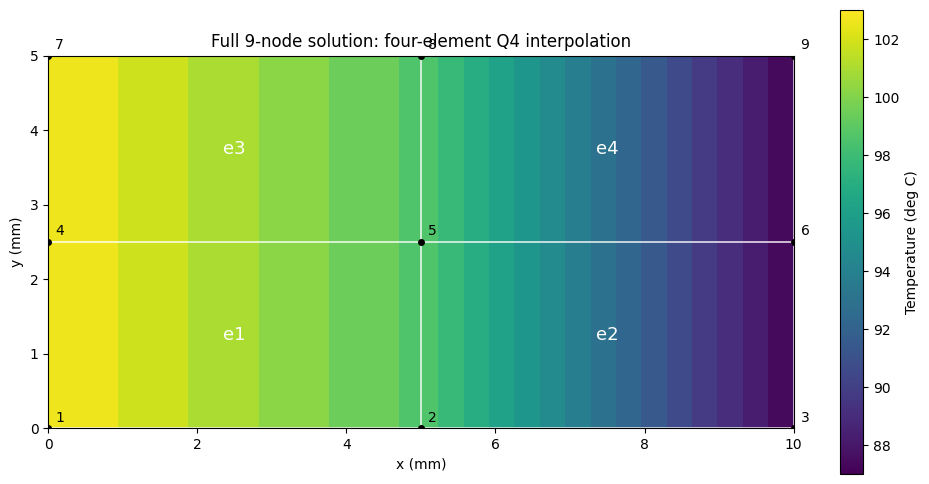

In [ ]:
# Compute temperature from local Q4 interpolation element by element.
from matplotlib.colors import Normalize

fig, ax = plt.subplots(figsize=(10,5))
all_levels = np.linspace(Tnum.min(), Tnum.max(), 21)
for e, nodes in enumerate(conn):
    row, col = divmod(e, 2)  # e1 and e2 bottom; e3 and e4 top
    X0 = col * Lx_mm/2
    Y0 = row * Ly_mm/2
    uu = np.linspace(-1,1,51)
    vv = np.linspace(-1,1,51)
    XI, ETA = np.meshgrid(uu,vv)
    shape_values = np.stack([
        (1-XI)*(1-ETA)/4,
        (1+XI)*(1-ETA)/4,
        (1+XI)*(1+ETA)/4,
        (1-XI)*(1+ETA)/4
    ],axis=-1)
    Tlocal = np.tensordot(shape_values, Tnum[nodes-1], axes=([-1],[0]))
    Xlocal = X0+(Lx_mm/2)*(1+XI)/2
    Ylocal = Y0+(Ly_mm/2)*(1+ETA)/2
    ax.contourf(Xlocal,Ylocal,Tlocal,levels=all_levels,cmap='viridis',extend='both')
    ax.text(X0+Lx_mm/4,Y0+Ly_mm/4,f'e{e+1}',ha='center',va='center',color='white',fontsize=13)

for xline in [0,Lx_mm/2,Lx_mm]:
    ax.axvline(xline,color='white',linewidth=1.2,alpha=.85)
for yline in [0,Ly_mm/2,Ly_mm]:
    ax.axhline(yline,color='white',linewidth=1.2,alpha=.85)
for inode in range(1,10):
    xp=((inode-1)%3)*Lx_mm/2
    yp=((inode-1)//3)*Ly_mm/2
    ax.plot(xp,yp,'o',color='black',markersize=4)
    ax.annotate(str(inode),(xp,yp),xytext=(5,5),textcoords='offset points',color='black')
fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(vmin=Tnum.min(),vmax=Tnum.max()),cmap='viridis'),ax=ax,label='Temperature (deg C)')
ax.set(xlabel='x (mm)',ylabel='y (mm)',title='Full 9-node solution: four-element Q4 interpolation')
ax.set_aspect('equal'); plt.tight_layout();plt.show()

## 12 · Check global heat conservation using the full solution

The global power balance is

$$\boxed{\dot Q_{\mathrm{conv}}=\dot Q_{\mathrm{in}}+\dot Q_{\mathrm{gen}}.}$$

Compute convection using the **two right-boundary element edges** $e_2$ and $e_4$ and the solved nodal temperatures. This uses element boundary integration, **not** a single assumed right-edge nodal temperature. In addition, verify the full nine-node residual.

In [ ]:
Q_in = q0_demo*thickness_mm*Ly_mm
Q_gen = volumetric_generation*thickness_mm*Lx_mm*Ly_mm

# Integrate theta along the convection edges of e2, e4 (local nodes 2 and 3).
# Each right edge length is b; trapezoidal integration is exact for Q4 edge fields.
b_mm = Ly_mm/2
Q_out = 0.0
for e in (1,3):
    nodes = conn[e]
    theta_bottom = theta_num[nodes[1]-1]
    theta_top = theta_num[nodes[2]-1]
    Q_out += h_demo*thickness_mm*b_mm*(theta_bottom+theta_top)/2

print(f'Heat entering through left edge : {Q_in:12.8f} W')
print(f'Volumetric heat generation      : {Q_gen:12.8f} W')
print(f'Convective heat leaving right   : {Q_out:12.8f} W')
print(f'Global energy imbalance         : {Q_out-Q_in-Q_gen:+.3e} W')
print(f'Maximum nodal equation residual : {max(abs(node_residual)):.3e} W')
assert np.isclose(Q_out,Q_in+Q_gen,atol=1e-10,rtol=1e-11)
assert np.allclose(Knum@theta_num,Fnum,atol=1e-10,rtol=1e-11)
print('Full-system equation residual and global energy balance both pass.')

Heat entering through left edge :   0.50000000 W
Volumetric heat generation      :  15.00000000 W
Convective heat leaving right   :  15.50000000 W
Global energy imbalance         : -3.908e-14 W
Maximum nodal equation residual : 2.132e-14 W
Full-system equation residual and global energy balance both pass.
